# Part 5 — Business recommendations

Turns the FDR-corrected results into a budget recommendation for the **$500K monthly** budget.
Inputs: `data/marketing_data.csv` and the results in `outputs/` from the earlier notebooks.

In [1]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATA = Path("data")
FIG = Path("figures")
OUT = Path("outputs")
for p in (DATA, FIG, OUT):
    p.mkdir(exist_ok=True)

ALPHA = 0.05

In [2]:
daily = pd.read_csv(DATA / "marketing_data.csv", parse_dates=["date"])
summary = pd.read_csv(OUT / "channel_summary.csv", index_col="channel")
cpa_results = pd.read_csv(OUT / "pairwise_cpa_ttests.csv")
roas_results = pd.read_csv(OUT / "pairwise_roas_ttests.csv")
fisher_results = pd.read_csv(OUT / "pairwise_conversion_rate_fisher.csv")
BUDGET = 500_000

## Step 8.1 — Significant findings (FDR-corrected)

In [3]:
print("CPA differences (t-test, FDR):")
sig = cpa_results[cpa_results["significant_fdr"]]
if sig.empty:
    print("  None. Smallest adjusted p-value:", f"{cpa_results['p_value_fdr'].min():.3f}")
for _, r in sig.iterrows():
    lower = r["group_a"] if r["mean_a"] < r["mean_b"] else r["group_b"]
    print(f"  {lower} has lower CPA by ${abs(r['difference']):.2f} (adj p {r['p_value_fdr']:.3g}, d {r['cohens_d']:.2f})")

print("\nROAS differences (t-test, FDR):")
print("  None." if not roas_results["significant_fdr"].any() else roas_results[roas_results["significant_fdr"]])

print("\nConversion-rate differences (Fisher, FDR):")
for _, r in fisher_results[fisher_results["significant_fdr"]].sort_values("p_value_fdr").iterrows():
    higher, lower = (r["group_a"], r["group_b"]) if r["rate_a"] > r["rate_b"] else (r["group_b"], r["group_a"])
    print(f"  {higher:>10} > {lower:<10} by {abs(r['difference']) * 100:.3f} pp "
          f"(adj p {r['p_value_fdr']:.2e}{', also Bonferroni' if r['significant_bonferroni'] else ''})")

CPA differences (t-test, FDR):
  None. Smallest adjusted p-value: 0.568

ROAS differences (t-test, FDR):
  None.

Conversion-rate differences (Fisher, FDR):
       Email > YouTube    by 0.056 pp (adj p 6.39e-09, also Bonferroni)
     Website > YouTube    by 0.048 pp (adj p 5.17e-07, also Bonferroni)
       Email > Instagram  by 0.045 pp (adj p 2.44e-06, also Bonferroni)
    Facebook > YouTube    by 0.042 pp (adj p 1.02e-05, also Bonferroni)
     Website > Instagram  by 0.037 pp (adj p 8.68e-05, also Bonferroni)
  Google Ads > YouTube    by 0.032 pp (adj p 9.54e-04, also Bonferroni)
    Facebook > Instagram  by 0.031 pp (adj p 1.05e-03, also Bonferroni)
       Email > Google Ads by 0.024 pp (adj p 1.36e-02)
  Google Ads > Instagram  by 0.021 pp (adj p 3.19e-02)


## Step 8.2 — Bootstrap 95% confidence intervals for daily CPA

In [4]:
boot_rng = np.random.default_rng(7)


def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):
    data = np.asarray(data)
    means = np.array([boot_rng.choice(data, size=len(data), replace=True).mean() for _ in range(n_bootstrap)])
    a = 1 - ci_level
    return np.percentile(means, 100 * a / 2), np.percentile(means, 100 * (1 - a / 2))


ci_rows = []
for ch, g in daily.groupby("channel"):
    lo, hi = bootstrap_ci(g["cpa"])
    ci_rows.append({"channel": ch, "mean_daily_cpa": g["cpa"].mean(), "ci_95_lower": lo, "ci_95_upper": hi})
ci = pd.DataFrame(ci_rows).sort_values("mean_daily_cpa")
ci.to_csv(OUT / "cpa_confidence_intervals.csv", index=False)
overlap = ci["ci_95_lower"].max() < ci["ci_95_upper"].min()
print("All six intervals share a common range:", overlap)
ci.round(2)

All six intervals share a common range: True


,channel,mean_daily_cpa,ci_95_lower,ci_95_upper
4,Website,283.6200,280.9600,286.0900
0,Email,285.0700,282.5100,287.6400
1,Facebook,285.5700,283.2400,287.9800
5,YouTube,286.4400,283.9000,289.2000
2,Google Ads,286.8000,284.2600,289.2900
3,Instagram,286.9300,284.3700,289.5800


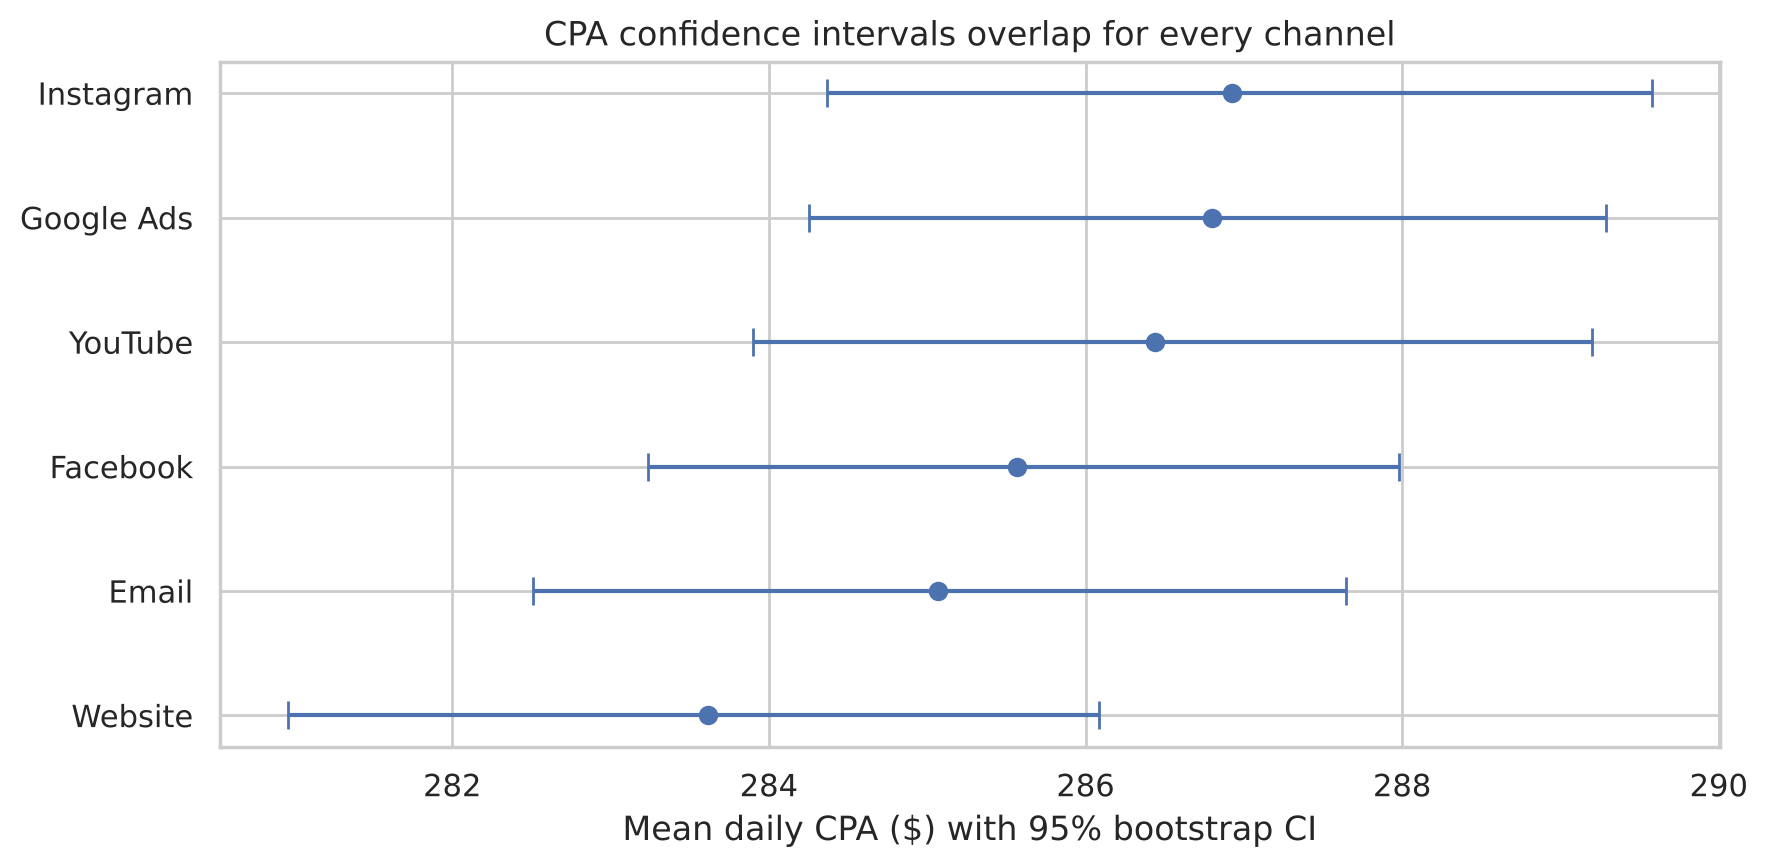

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(ci["mean_daily_cpa"], ci["channel"],
            xerr=[ci["mean_daily_cpa"] - ci["ci_95_lower"], ci["ci_95_upper"] - ci["mean_daily_cpa"]],
            fmt="o", capsize=5, color="#4C72B0")
ax.set(xlabel="Mean daily CPA ($) with 95% bootstrap CI", title="CPA confidence intervals overlap for every channel")
fig.tight_layout()
fig.savefig(FIG / "cpa_confidence_intervals.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 8.3 — Composite score and budget allocation

**Ranking.** Each channel is ranked from 1 (worst) to 6 (best) on three metrics:
- CPA, where lower is better, so the ranks are inverted;
- ROAS;
- conversion rate.

The weights are **CPA 40%, ROAS 40%, conversion rate 20%**. CPA and ROAS drive the money; conversion rate is a supporting funnel metric.

**Constraints.** The statistics say the channels perform the same, so the ranking can't justify large moves. We therefore limit how far the allocation strays from an even split:
- An even split is $83.3K per channel (16.7%).
- Each channel moves away from the even split in proportion to how far its composite score is from the average. The tilt is scaled so the best and worst channels move by exactly **±10%** ($75.0K–$91.7K), and the total is always $500K.

A naive allocation, purely proportional to score with no limits, is shown for contrast. It's what the decision would look like without the statistics.

In [6]:
ranks = pd.DataFrame(index=summary.index)
ranks["cpa_rank"] = summary["cpa"].rank(ascending=False)          # lowest CPA gets 6
ranks["roas_rank"] = summary["roas"].rank(ascending=True)
ranks["conversion_rate_rank"] = summary["conversion_rate"].rank(ascending=True)
weights = {"cpa_rank": 0.4, "roas_rank": 0.4, "conversion_rate_rank": 0.2}
ranks["composite_score"] = sum(ranks[c] * w for c, w in weights.items())
ranks = ranks.sort_values("composite_score", ascending=False)


def tilted_allocation(scores, total, max_tilt=0.10, step=100):
    # Even split, tilted by each channel's distance from the mean score; extremes move exactly ±max_tilt.
    even = total / len(scores)
    dev = scores - scores.mean()
    alloc = even * (1 + max_tilt * dev / dev.abs().max())
    alloc = (alloc / step).round() * step
    alloc.iloc[0] += total - alloc.sum()          # put any rounding remainder on the top-ranked channel
    return alloc


ranks["naive_allocation"] = ranks["composite_score"] / ranks["composite_score"].sum() * BUDGET
ranks["recommended_allocation"] = tilted_allocation(ranks["composite_score"], BUDGET)
ranks["recommended_pct"] = ranks["recommended_allocation"] / BUDGET
ranks["change_vs_even_split"] = ranks["recommended_allocation"] - BUDGET / len(ranks)
ranks.to_csv(OUT / "budget_allocation.csv")
assert abs(ranks["recommended_allocation"].sum() - BUDGET) < 1
print(f"Total allocated: ${ranks['recommended_allocation'].sum():,.0f}")
ranks.round(2)

Total allocated: $500,000


,cpa_rank,roas_rank,conversion_rate_rank,composite_score,naive_allocation,recommended_allocation,recommended_pct,change_vs_even_split
channel,,,,,,,,
Website,6.0000,5.0000,5.0000,5.4000,"128,571.4300","91,700.0000",0.1800,"8,366.6700"
Facebook,4.0000,6.0000,4.0000,4.8000,"114,285.7100","89,000.0000",0.1800,"5,666.6700"
Email,5.0000,2.0000,6.0000,4.0000,"95,238.1000","85,500.0000",0.1700,"2,166.6700"
YouTube,3.0000,3.0000,1.0000,2.6000,"61,904.7600","79,400.0000",0.1600,"-3,933.3300"
Google Ads,1.0000,4.0000,3.0000,2.6000,"61,904.7600","79,400.0000",0.1600,"-3,933.3300"
Instagram,2.0000,1.0000,2.0000,1.6000,"38,095.2400","75,000.0000",0.1500,"-8,333.3300"


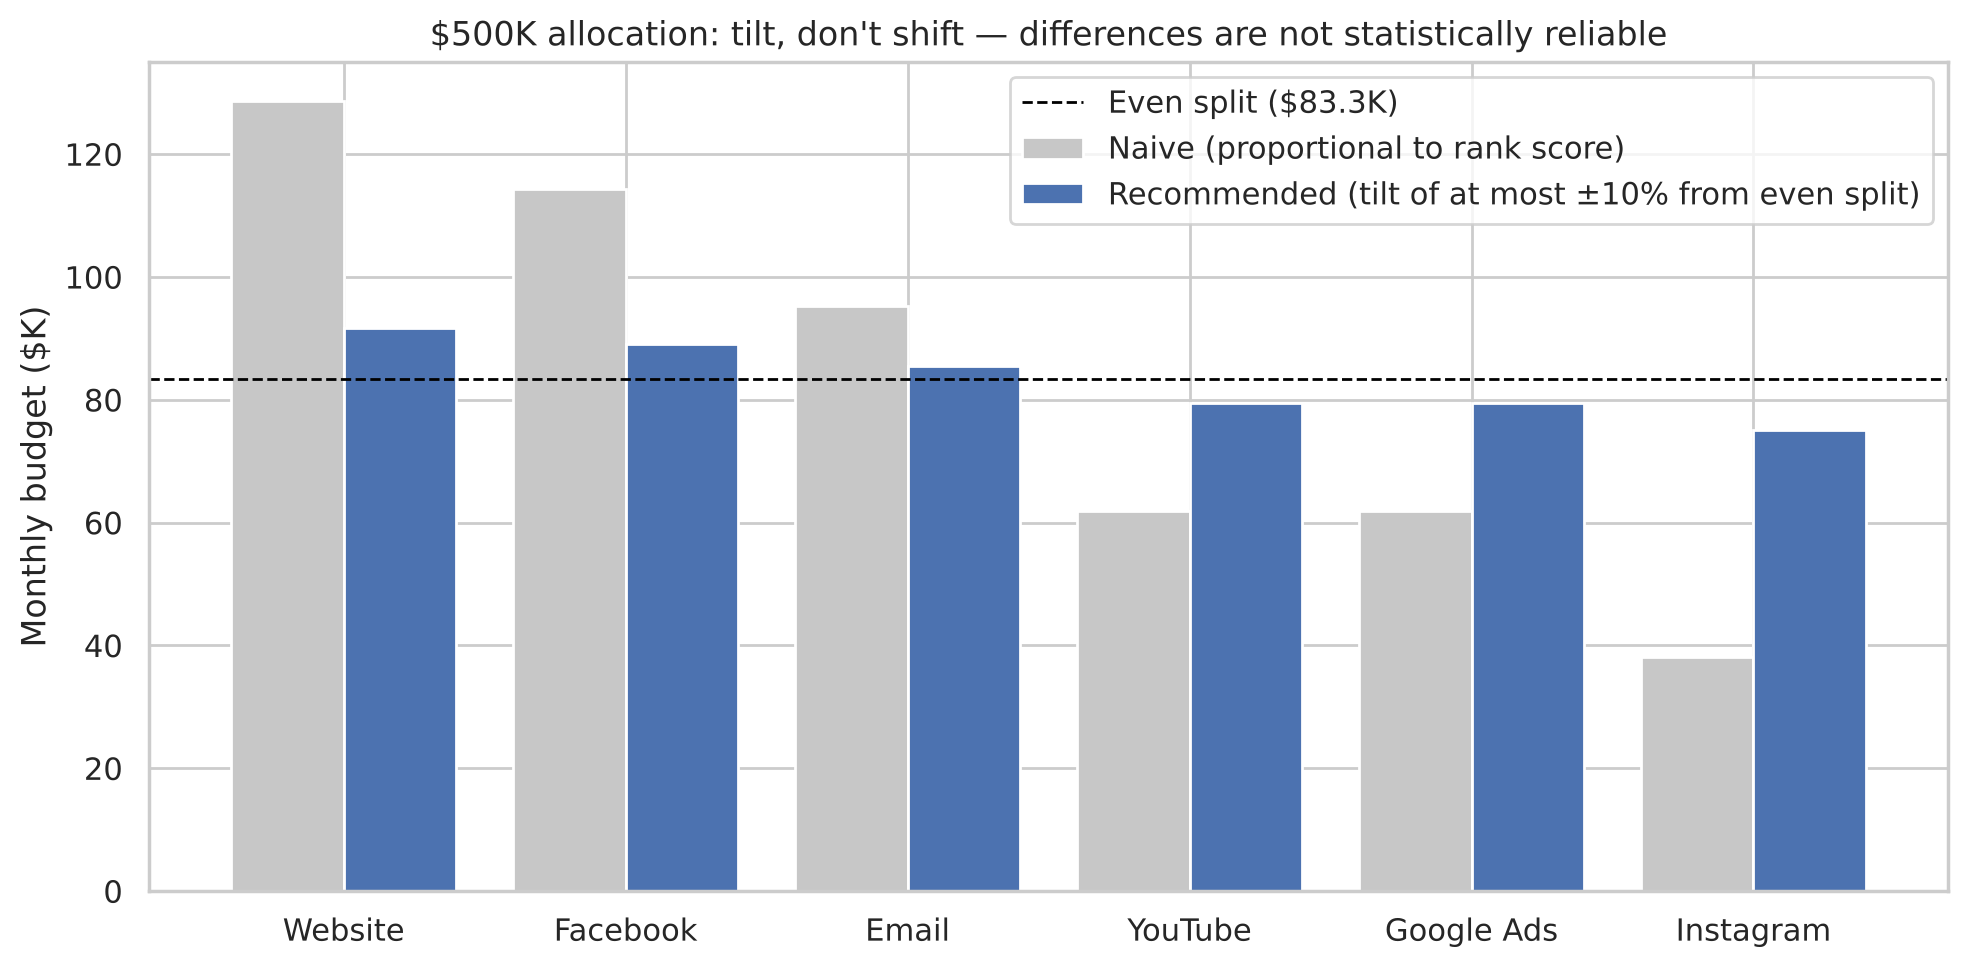

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(ranks))
ax.bar(x - 0.2, ranks["naive_allocation"] / 1000, 0.4, label="Naive (proportional to rank score)", color="#C7C7C7")
ax.bar(x + 0.2, ranks["recommended_allocation"] / 1000, 0.4, label="Recommended (tilt of at most ±10% from even split)", color="#4C72B0")
ax.axhline(BUDGET / len(ranks) / 1000, color="black", ls="--", lw=1, label="Even split ($83.3K)")
ax.set_xticks(x, ranks.index)
ax.set(ylabel="Monthly budget ($K)", title="$500K allocation: tilt, don't shift — differences are not statistically reliable")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "budget_allocation.png", dpi=150, bbox_inches="tight")
plt.show()

### Prioritisation

- **Small tilt toward the top composite scorers, Facebook and Website.** They're slightly ahead on ROAS and CPA. That lead isn't statistically reliable, so their extra budget is capped at about +10%.
- **No channel is cut hard.** The bottom scorers (Instagram, then YouTube and Google Ads, tied) also aren't reliably worse.
- **Use the tilt as a test.** Run the tilt as a planned 90-day test on one pre-registered metric (CPA), as the power analysis recommends, and keep it only if CPA improves by at least 5%.
- **Look beyond channel.** If one dimension shows real differences, segmenting by campaign type, audience or region may find bigger levers than channel does.

The executive memo (`executive_memo.md`) covers this together with the caveats.